# Word vectors and sentiment

**Barda Soltani Moakhar and Setayesh Heydari**  
Linear Algebra | Instructor: **Maryam Ramezani**

A sparse word-context matrix becomes a compact vector space through SVD. We inspect its geometry and test frozen word vectors as inputs to a sentiment classifier. Full numerical results are recorded even when the course CSVs are unavailable locally.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "laml").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "laml").exists():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
RECOMPUTE = False

def read_result(name):
    return json.loads((ROOT / "results" / name).read_text())

def show_figure(name):
    from PIL import Image
    display(Image.open(ROOT / "results" / "figures" / name))

In [2]:
if RECOMPUTE:
    from laml.experiments import run
    run("embeddings")
    run("sentiment")
embedding_metrics = read_result("embedding_metrics.json")
sentiment_metrics = read_result("sentiment_metrics.json")
display(pd.DataFrame([{k:embedding_metrics[k] for k in ["source_rows","retained_sentences","vocabulary_size","cooccurrence_nonzeros","ppmi_nonzeros","dimensions"]}]).T.rename(columns={0:"Value"}))

,Value
source_rows,158314
retained_sentences,93206
vocabulary_size,3000
cooccurrence_nonzeros,545887
ppmi_nonzeros,472076
dimensions,64


## Exact counts on a small example

The context window is measured in token positions. Sentences remain separate. A pair contributes both directions, so the matrix is symmetric. The following calculation is independent of the external dataset.

In [3]:
from laml.text import cooccurrence, ppmi
words, counts, _ = cooccurrence([["garden", "green", "trees"], ["garden", "green", "flowers"]], min_count=1, window=1)
display(pd.DataFrame(counts.toarray(),index=words,columns=words))
display(pd.DataFrame(ppmi(counts).toarray(),index=words,columns=words).round(3))

,garden,green,flowers,trees
garden,0.0,2.0,0.0,0.0
green,2.0,0.0,1.0,1.0
flowers,0.0,1.0,0.0,0.0
trees,0.0,1.0,0.0,0.0


,garden,green,flowers,trees
garden,0.000,0.693,0.000,0.000
green,0.693,0.000,0.693,0.693
flowers,0.000,0.693,0.000,0.000
trees,0.000,0.693,0.000,0.000


## PPMI and SVD

We replace raw counts with $\max(\log(C_{ij}N/(C_{i\cdot}C_{\cdot j})),0)$ at observed entries. The raw-count baseline uses $U_k$; the PPMI space uses $U_k\Sigma_k^{1/2}$. Rows become word vectors. This comparison changes both weighting and coordinate scaling.

Cosine similarity compares directions. Nearest neighbors exclude the query token. The analogy $a:b::c:?$ uses $b-a+c$ and excludes all three input words.

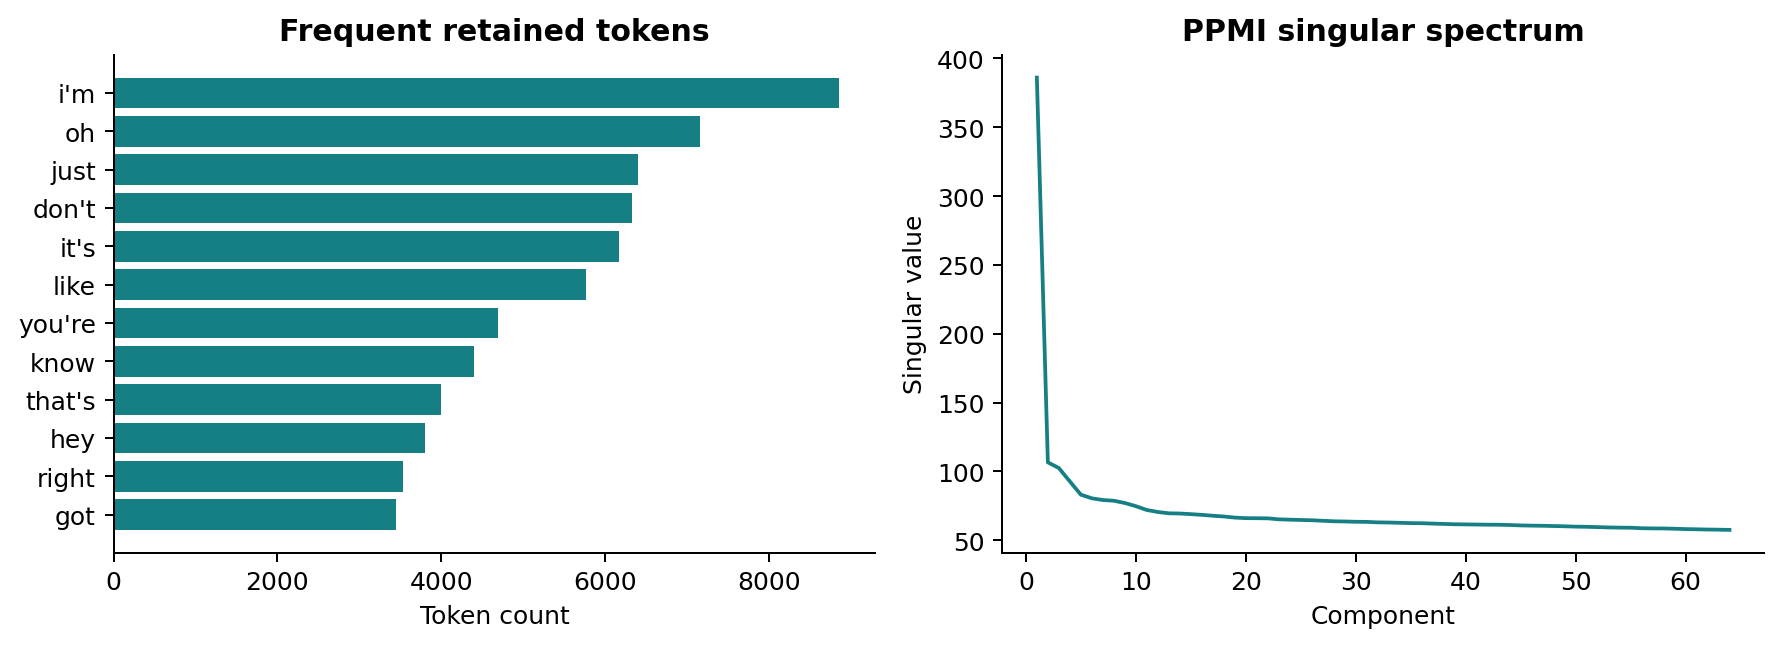

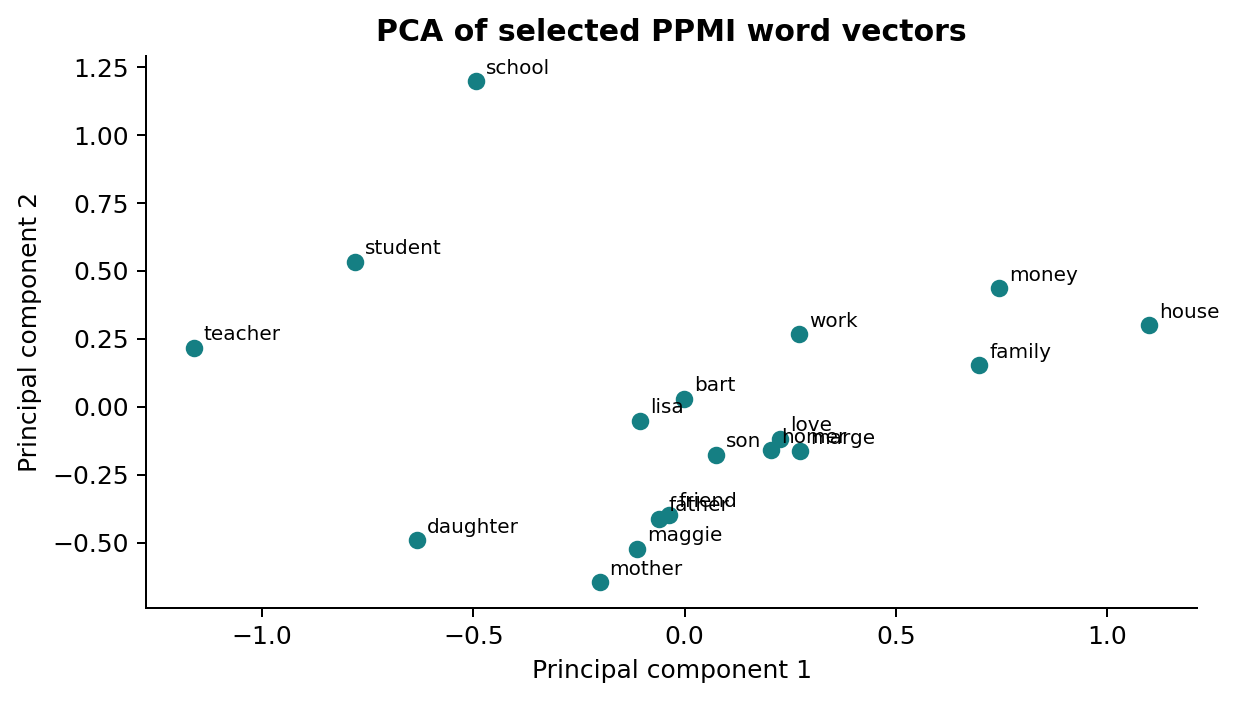

,method,dimensions,query,rank,neighbor,cosine
50,Count SVD (U),64,homer,1,abe,0.729175
51,Count SVD (U),64,homer,2,abraham,0.706961
52,Count SVD (U),64,homer,3,mrs,0.699884
53,Count SVD (U),64,homer,4,mr,0.653974
54,Count SVD (U),64,homer,5,jay,0.483111
125,PPMI SVD (U sqrt(S)),64,homer,1,marge,0.833166
126,PPMI SVD (U sqrt(S)),64,homer,2,bart,0.750607
127,PPMI SVD (U sqrt(S)),64,homer,3,simpson,0.712325
128,PPMI SVD (U sqrt(S)),64,homer,4,sorry,0.676439
129,PPMI SVD (U sqrt(S)),64,homer,5,i'm,0.675106


In [4]:
show_figure("embeddings.png")
show_figure("word_projection.png")
neighbors = pd.read_csv(ROOT / "results/word_neighbors.csv")
display(neighbors[(neighbors["dimensions"]==64) & (neighbors["query"]=="homer")])

In [5]:
from laml.text import VectorSpace
toy = VectorSpace(["man", "woman", "king", "queen"], [[1,0],[0,1],[2,0],[1,1]])
print("Toy analogy man:woman::king:?", toy.analogy("man","woman","king"))
evaluation = embedding_metrics["analogy_evaluation"]
display(pd.DataFrame(evaluation["predictions"]))
print(f"Coverage: {evaluation['covered']}/{evaluation['total']}; correct: {evaluation['correct']}")
print("GloVe status:", embedding_metrics["glove_status"])

,question,prediction,status
0,"[paris, france, toronto, canada]",None,out_of_vocabulary
1,"[australia, dollar, japan, yen]",None,out_of_vocabulary
2,"[chicago, illinois, stockton, california]",None,out_of_vocabulary
3,"[brother, sister, father, mother]",mother,evaluated
4,"[apparent, apparently, rapid, rapidly]",None,out_of_vocabulary
5,"[great, greater, tough, tougher]",None,out_of_vocabulary
6,"[easy, easiest, lucky, luckiest]",None,out_of_vocabulary
7,"[think, thinking, read, reading]",written,evaluated
8,"[switzerland, swiss, turkey, turkish]",None,out_of_vocabulary
9,"[walking, walked, swimming, swam]",None,out_of_vocabulary


Toy analogy man:woman::king:? [('queen', 0.9999999999999998)]
Coverage: 2/12; correct: 1
GloVe status: not_run_external_vectors_not_supplied


## A three-dimensional projection

A third principal component can separate points that overlap in two dimensions. This view is still a projection and does not replace similarity measurements in the original vector space.

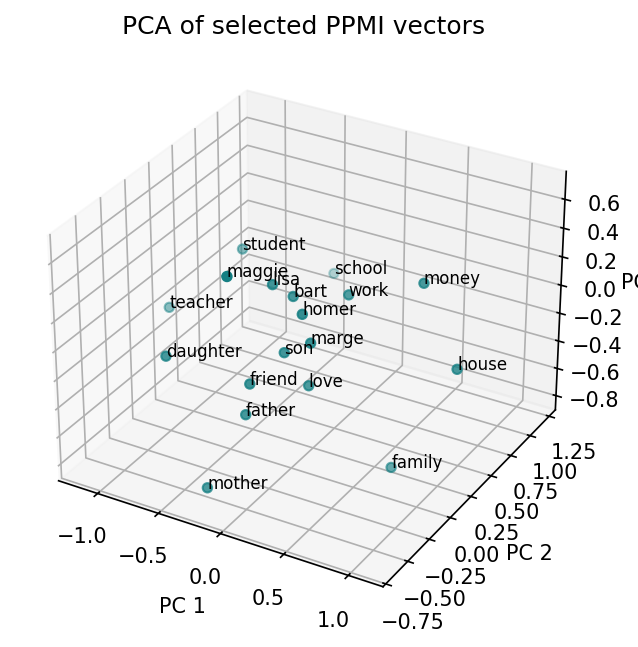

In [6]:
import matplotlib.pyplot as plt
projection = pd.read_csv(ROOT / "results/word_projection_3d.csv")
figure = plt.figure(figsize=(8, 5))
axis = figure.add_subplot(111, projection="3d")
axis.scatter(projection["pc1"],projection["pc2"],projection["pc3"],color="#157f83")
for row in projection.itertuples():
    axis.text(row.pc1,row.pc2,row.pc3,row.word,fontsize=8)
axis.set(xlabel="PC 1",ylabel="PC 2",zlabel="PC 3",title="PCA of selected PPMI vectors")
display(figure)
plt.close(figure)

## Frozen embeddings for sentiment

The LSTM receives 32-dimensional dialogue embeddings and the first 100 tokens of each review. Unknown tokens map to zero. Padding preserves the hidden and cell states, and reviews start with independent zero states. Validation selects the epoch; the test set is used for the final evaluation.

The TF-IDF baseline learns its vocabulary only from training reviews and uses unigram and bigram features. It sees full reviews. This comparison changes both representation and classifier.

,Value
seed,42
source_rows,5000
deduplicated_rows,4997
train,2997
validation,1000
test,1000
split,60/20/20 stratified random split after normalized-text deduplication
max_tokens,100
embedding_dimensions,32
lstm_hidden_size,24


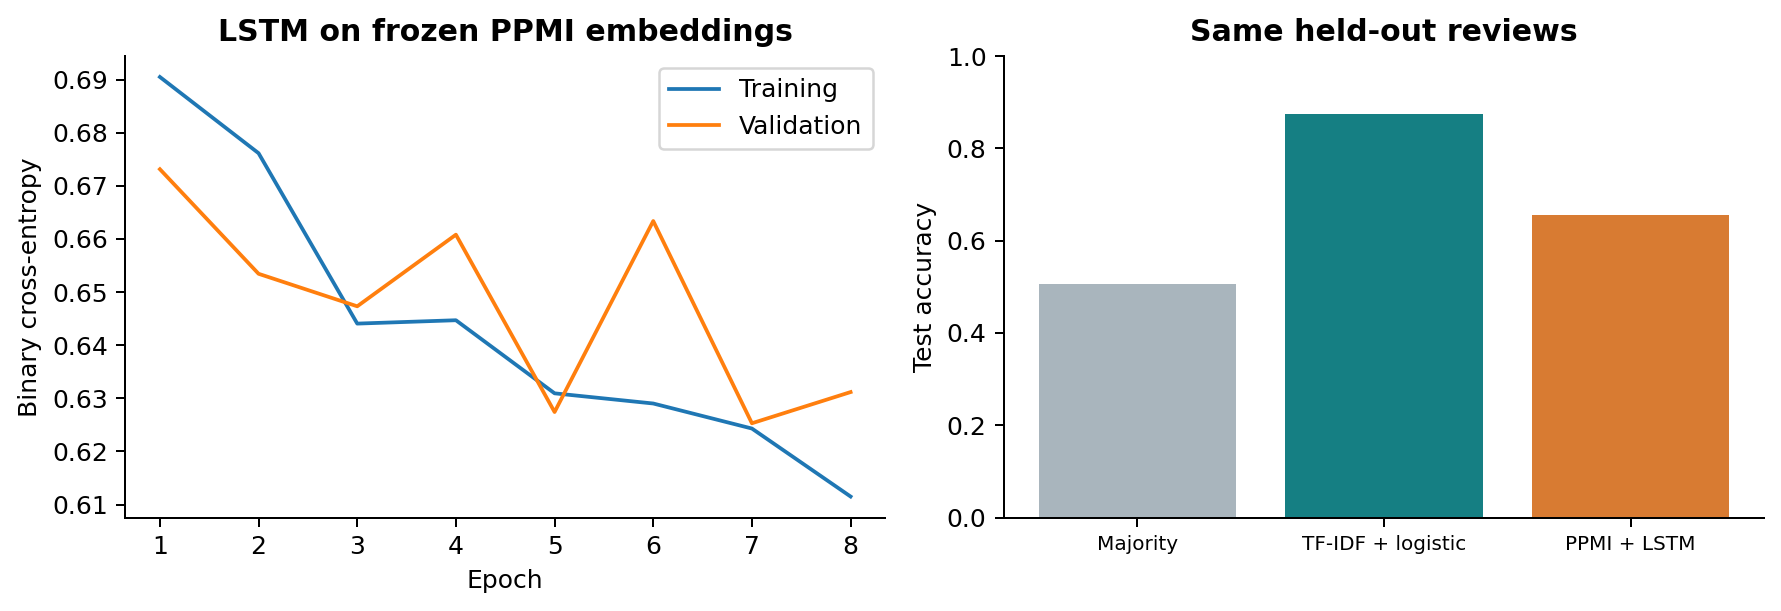

tfidf_prediction: 0.874
lstm_prediction: 0.655


In [7]:
display(pd.DataFrame([sentiment_metrics]).T.rename(columns={0:"Value"}))
predictions = pd.read_csv(ROOT / "results/sentiment_test_predictions.csv")
for column in ["tfidf_prediction", "lstm_prediction"]:
    accuracy = (predictions[column] == predictions["true_label"]).mean()
    print(f"{column}: {accuracy:.3f}")
show_figure("sentiment.png")

## Interpretation

The LSTM outperforms the majority label but trails TF-IDF substantially. Its low vocabulary coverage and truncated input are plausible contributors. The small analogy diagnostic has only two covered questions, so covered accuracy is not a useful general benchmark.

Optional pretrained-vector analysis is available through `scripts/evaluate_glove.py`. It supports GloVe loading, analogies, PCA, and t-SNE. Those pretrained vectors are an external input and were not used in the recorded run.